**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**10 | Raw-IMU Temporal Classification with PyTorch**

![Raw-IMU temporal classification with PyTorch workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/10_workflow.svg)

**Objective:** Train a compact 1D-CNN on six-channel HARTH acceleration windows and evaluate its bounded, participant-disjoint Development performance.

**Dataset:** The pinned HARTH v2.0 Development cohort, with up to 500 label-pure, two-second windows sampled per participant.

**Notebook Scope:** Fit channel scaling on Train only, train the temporal CNN for five epochs and inspect Validation Macro F1 and class-specific errors. Reserved Test recordings S023 and S032 are not loaded. Sampling and evaluation differ from the full-cohort classical ML comparison, so direct model rankings across these protocols are not justified.

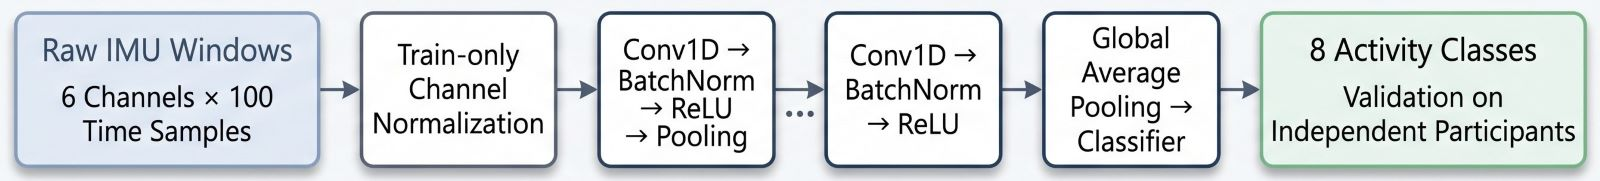

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------------ 3. Deep Learning Framework -------------------------
import torch

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# ------------------ 5. HARTH and Shared Research Utilities -------------------
from core.output_download import download_outputs_from_colab
from harth_data import (
    HARTH_SUBJECTS,
    ACTIVITY_NAMES,
    prepare_harth_window_cohort,
)
from core.data_splitting import split_group_indices
from core.temporal_cnn import TemporalCNN, train_temporal_cnn

# ------------------- 6. Training Device and Output Setup ---------------------
from core.computer_device import computer_device
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
device = computer_device()
DEVICE = device.type
print("Repository root:", root)
print("Research output directory:", output_dir)

Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
nvidia-smi is not available in this environment.
PyTorch version: 2.11.0+cpu
CUDA is not available to PyTorch; using CPU.
Selected compute device: cpu
Repository root: /content/human-movement-intelligence
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Define the Bounded Raw-Signal Experiment**

Use all 29 Development participants with a deterministic cap of 500 eligible windows per person, sampled without using labels. The saved cohort contains 14,201 windows; this computational cap can change activity representation and does not balance the classes.

In [3]:
# ================== 02. Construct Bounded Raw-Window Cohort ==================

# ---------------------- 1. Configure Development Cohort ----------------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))
MAX_WINDOWS_PER_SUBJECT = 500
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# --------------------- 2. Prepare Bounded Signal Windows ---------------------
X, y, metadata, overview = prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    max_windows_per_subject=MAX_WINDOWS_PER_SUBJECT,  # Limit sampling within each Development participant.
    window_size=100, step_size=50, sampling_rate=50,
)

# ----------------------- 3. Cohort and Tensor Summary ------------------------
display(overview)

print("Real raw IMU tensor:", X.shape)
print("Label vector:", y.shape)
print("Subjects:", metadata["subject_id"].nunique())


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,subject_id,raw_samples,candidate_retained_windows,eligible_windows,sampled_windows,excluded_out_of_task_windows,observed_sampled_classes
0,S006,408709,7441,6708,500,733,7
1,S008,418989,7564,7392,500,172,5
2,S009,154464,2885,201,201,2684,4
3,S010,351649,6077,6077,500,0,6
4,S012,382414,7309,7309,500,0,8
5,S013,369077,6451,6402,500,49,8
6,S014,366487,6409,6299,500,110,8
7,S015,418392,7626,7453,500,173,8
8,S016,355418,6484,6272,500,212,7
9,S017,366609,6841,6678,500,163,8


Real raw IMU tensor: (14201, 6, 100)
Label vector: (14201,)
Subjects: 29


**03. Create Subject-Disjoint Train and Validation Groups**

Split whole participants rather than overlapping windows. The `unused_development` partition contains three Development participants and is distinct from reserved final Test identities S023 and S032.

In [4]:
# ================ 03. Separate Train and Validation Subjects =================

# ----------------- 1. Create Participant-Disjoint Partitions -----------------
parts = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,  # Unused Development subset, not the reserved Test cohort.
)
group_names = {
    name: sorted(metadata.iloc[idx]["subject_id"].unique().tolist())
    for name, idx in parts.items()
}

# ------------------------ 2. Verify Group Separation -------------------------
assert not (set(group_names["train"]) & set(group_names["validation"]))
assert not (set(group_names["train"]) & set(group_names["test"]))
assert not (set(group_names["validation"]) & set(group_names["test"]))

# ------------------- 3. Extract Train and Validation Data --------------------
train_rows = parts["train"]
validation_rows = parts["validation"]

X_train, y_train = X[train_rows], y[train_rows]
X_validation, y_validation = X[validation_rows], y[validation_rows]

# --------------------------- 4. Partition Summary ----------------------------
display(pd.DataFrame([
    {"role": "Train", "subjects": len(group_names["train"]),
     "windows": len(train_rows), "subject_ids": ", ".join(group_names["train"])},
    {"role": "Validation", "subjects": len(group_names["validation"]),
     "windows": len(validation_rows), "subject_ids": ", ".join(group_names["validation"])},
    {"role": "Unused development", "subjects": len(group_names["test"]),
     "windows": len(parts["test"]), "subject_ids": ", ".join(group_names["test"])},
]))

print("Original reserved final Test loaded: NO")


Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows


,role,subjects,windows,subject_ids
0,Train,20,10000,"S006, S010, S013, S014, S015, S017, S018, S020..."
1,Validation,6,2701,"S009, S012, S019, S022, S036, S037"
2,Unused development,3,1500,"S008, S016, S021"


Original reserved final Test loaded: NO


**04. Audit Source Classes and Temporal Model Input**

Check that Train contains all eight target classes and that the CNN input follows `(batch, channels, time)`, rather than the previously engineered 30-feature representation.

In [5]:
# ==================== 04. Audit Classes and Raw CNN Input ====================

# --------------------- 1. Check Training Class Coverage ----------------------
counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "validation": pd.Series(y_validation).value_counts(),
}).reindex(TASK_CLASSES, fill_value=0).fillna(0).astype(int)

counts.index = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]
display(counts)

# ------------------ 2. Inspect CNN Input and Output Shapes -------------------
assert (counts["train"] > 0).all(), "Training class coverage is incomplete."

model_preview = TemporalCNN(in_channels=6, n_classes=8)
example_output = model_preview(torch.from_numpy(X_train[:4]))

print("Example CNN output shape:", tuple(example_output.shape))
print("Untrained classifier output is logits, not probabilities.")


,train,validation
1: Walking,2987,453
2: Running,940,78
3: Shuffling,169,15
4: Stairs ascending,156,30
5: Stairs descending,145,32
6: Standing,1502,536
7: Sitting,3240,1363
8: Lying,861,194


Example CNN output shape: (4, 8)
Untrained classifier output is logits, not probabilities.


**05. Train the Compact 1D-CNN with Train-Only Scaling**

Estimate channel means and standard deviations from Train windows only. Train the CNN for five epochs using raw signal sequences; CPU is the default device, with CUDA used when available. This is a bounded feasibility experiment, not a hyperparameter-matched benchmark against classical models.

In [6]:
# =================== 05. Train the Compact PyTorch 1D-CNN ====================

# ------------------------ 1. Configure Model Training ------------------------
EPOCHS = 5
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Training device:", DEVICE)

# ------------------- 2. Train CNN with Train-Only Scaling --------------------
model, history, validation_pred, scaling = train_temporal_cnn(
    X_train=X_train, y_train=y_train,
    X_validation=X_validation, y_validation=y_validation,
    classes=TASK_CLASSES,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE, seed=42, device=DEVICE,  # Fit channel normalisation on Train data only.
)

# -------------------------- 3. Training Diagnostics --------------------------
display(history.round(4))
print("Channel means fitted from Train:", np.round(scaling["channel_mean"], 4))


Training device: cpu
Epoch 1/5 | loss=0.7939 | validation Macro F1=0.5911
Epoch 2/5 | loss=0.3313 | validation Macro F1=0.5975
Epoch 3/5 | loss=0.2590 | validation Macro F1=0.6015
Epoch 4/5 | loss=0.2173 | validation Macro F1=0.6263
Epoch 5/5 | loss=0.1918 | validation Macro F1=0.6659


,epoch,train_loss,validation_macro_f1,validation_accuracy,validation_balanced_accuracy
0,1,0.7939,0.5911,0.9337,0.5987
1,2,0.3313,0.5975,0.9415,0.6040
2,3,0.2590,0.6015,0.9482,0.6079
3,4,0.2173,0.6263,0.9515,0.6231
4,5,0.1918,0.6659,0.9530,0.6459


Channel means fitted from Train: [-0.8837 -0.0212 -0.1242 -0.711  -0.0967 -0.3982]


**06. Visualise Learning Curves and Validation Scores**

Plot training loss and Validation Macro F1 in separate panels. Report the final epoch without selecting a model using reserved Test data.

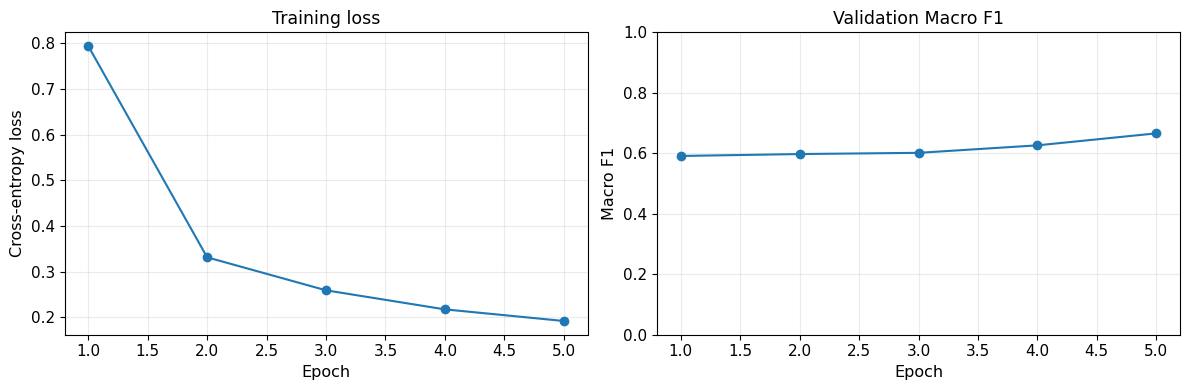

In [7]:
# =============== 06. Visualise Training and Validation Trends ================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].grid(alpha=0.25)
axes[1].plot(history["epoch"], history["validation_macro_f1"], marker="o")
axes[1].set(title="Validation Macro F1", xlabel="Epoch",
            ylabel="Macro F1", ylim=(0, 1))
axes[1].grid(alpha=0.25)
fig.tight_layout()
save_figure(fig, output_dir / "10_cnn_training_validation_curves.png")
plt.show()


**07. Inspect Last-Epoch Activity Classification Errors**

Examine the eight-class confusion matrix and class-specific scores for the bounded Development Validation participants.

,precision,recall,f1-score,support
Walking,0.885,0.949,0.916,453.000
Running,0.987,1.000,0.994,78.000
Shuffling,0.000,0.000,0.000,15.000
Stairs ascending,1.000,0.100,0.182,30.000
Stairs descending,1.000,0.188,0.316,32.000
Standing,0.935,0.937,0.936,536.000
Sitting,0.975,0.999,0.987,1363.000
Lying,1.000,0.995,0.997,194.000
accuracy,0.953,0.953,0.953,0.953
macro avg,0.848,0.646,0.666,2701.000


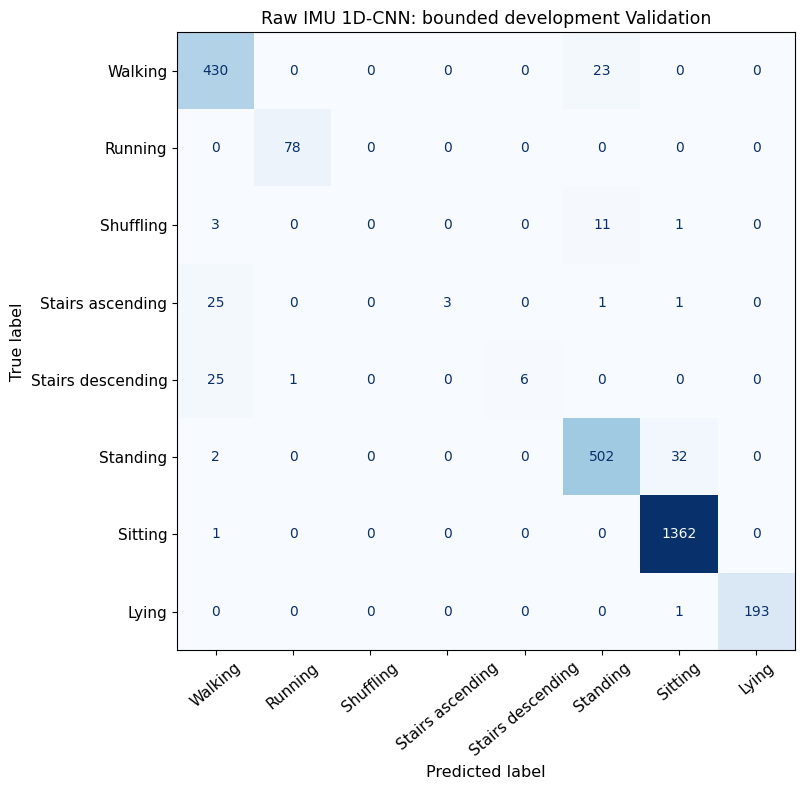

In [8]:
# ============== 07. Inspect Validation Class-Level Predictions ===============

# -------------------- 1. Validation Classification Report --------------------
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

report = classification_report(
    y_validation, validation_pred,
    labels=TASK_CLASSES,
    target_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    output_dict=True, zero_division=0,
)

report_table = pd.DataFrame(report).T
display(report_table.round(3))

# ------------------ 2. Confusion Matrix and Error Analysis -------------------
confusion = confusion_matrix(y_validation, validation_pred, labels=TASK_CLASSES)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
).plot(ax=ax, cmap="Blues", xticks_rotation=40, colorbar=False)

ax.set_title("Raw IMU 1D-CNN: bounded development Validation")
fig.tight_layout()
save_figure(fig, output_dir / "10_cnn_validation_confusion.png")
plt.show()


**08. Scientific Quality Gate and Research Limitations**

Check the raw-signal tensor, participant separation, predictions and five-epoch training history. The saved final-epoch Validation Macro F1 is 0.6659. This is Development evidence only and is not directly comparable to the full-cohort, five-fold classical ML evaluation.

In [9]:
# ================ 08. Scientific Quality Gate and Limitations ================

# ----------------- 1. Verify Prediction and Group Integrity ------------------
assert len(X_train) == len(y_train) and len(X_validation) == len(y_validation)
assert X_train.shape[1:] == X_validation.shape[1:] == (6, 100)
assert not (set(group_names["train"]) & set(group_names["validation"]))
assert set(np.unique(validation_pred)).issubset(TASK_CLASSES)
assert history["validation_macro_f1"].between(0, 1).all()
assert len(history) == EPOCHS

# ------------------- 2. Quality Gate and Evidence Boundary -------------------
print("Raw-signal PyTorch pipeline: PASSED")
print("Validated development subjects:", len(group_names["validation"]))
print("Unused development subjects:", len(group_names["test"]))
print("Original reserved Test loaded/scored: NO")
print("Matched full-cohort CNN vs Random Forest benchmark: NOT PERFORMED")

# -------------------- 3. Save Validation-Only Research Results ---------------
overview.to_csv(output_dir / "10_development_cohort_summary.csv", index=False)
partition_summary = pd.DataFrame([
    {"role": role, "subject_id": subject}
    for role, people in group_names.items()
    for subject in people
])
partition_summary.to_csv(
    output_dir / "10_development_partition_membership.csv", index=False
)
counts.rename_axis("activity").reset_index().to_csv(
    output_dir / "10_training_validation_class_coverage.csv", index=False
)
history.to_csv(output_dir / "10_cnn_training_history.csv", index=False)
report_table.rename_axis("class_or_metric").reset_index().to_csv(
    output_dir / "10_cnn_validation_classification_report.csv", index=False
)
pd.DataFrame(confusion, index=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
             columns=[ACTIVITY_NAMES[c] for c in TASK_CLASSES]).rename_axis(
    "true_activity"
).to_csv(output_dir / "10_cnn_validation_confusion_counts.csv")
pd.DataFrame({
    "subject_id": metadata.iloc[validation_rows]["subject_id"].to_numpy(),
    "true_source_code": y_validation,
    "predicted_source_code": validation_pred,
}).to_csv(output_dir / "10_cnn_validation_predictions.csv", index=False)

scaling_table = pd.DataFrame({
    "channel_index": np.arange(len(scaling["channel_mean"])),
    "train_only_mean": scaling["channel_mean"],
    "train_only_std": scaling["channel_std"],
})
scaling_table.to_csv(output_dir / "10_cnn_train_only_scaling.csv", index=False)

# Store the completed pilot's weights and reconstruction settings locally.
# The .pt extension is Git-ignored, independently of its actual file size.
torch.save({
    "model_state_dict": {
        name: parameter.detach().cpu()
        for name, parameter in model.state_dict().items()
    },
    "architecture": {
        "name": "TemporalCNN", "in_channels": 6, "n_classes": 8,
        "hidden_channels": 32,
    },
    "task_classes": list(TASK_CLASSES),
    "training": {
        "epochs": EPOCHS, "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE, "seed": 42,
    },
    "train_only_channel_mean": scaling["channel_mean"].tolist(),
    "train_only_channel_std": scaling["channel_std"].tolist(),
}, output_dir / "10_cnn_pilot_checkpoint.pt")
print("Saved bounded Development-only CNN evidence in:", output_dir)

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="10")

Raw-signal PyTorch pipeline: PASSED
Validated development subjects: 6
Unused development subjects: 3
Original reserved Test loaded/scored: NO
Matched full-cohort CNN vs Random Forest benchmark: NOT PERFORMED
Saved bounded Development-only CNN evidence in: /content/human-movement-intelligence/wearable_activity_recognition/output
------------------------------------------------------------------------
Notebook stage: 10
Files packaged: 11
  + 10_cnn_pilot_checkpoint.pt
  + 10_cnn_train_only_scaling.csv
  + 10_cnn_training_history.csv
  + 10_cnn_training_validation_curves.png
  + 10_cnn_validation_classification_report.csv
  + 10_cnn_validation_confusion.png
  + 10_cnn_validation_confusion_counts.csv
  + 10_cnn_validation_predictions.csv
  + 10_development_cohort_summary.csv
  + 10_development_partition_membership.csv
  + 10_training_validation_class_coverage.csv
Download ZIP from Colab Contents: /content/wearable_activity_recognition_Stage_10_Outputs.zip
GitHub Commit/Push performed: NO
